# CardioIA Fase 4 — Ir Além 1: Ética, Governança e Fairness em Visão Computacional
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samuelnrocha/CardioIA_Fase4/blob/main/notebooks/03_etica_e_fairness_visao_computacional.ipynb)

**Instituição:** FIAP — Faculdade de Informática e Administração Paulista  
**Grupo:** **Data Health Solutions**  

---

## 1. Fundamentação Bioética e Auditoria de Vieses Demográficos
Estudos seminais em radiologia computacional (*Seyyed-Kalantari et al., Nature Medicine 2021*) demonstraram que redes neurais convolucionais treinadas em grandes bases públicas como o **NIH Chest X-ray** podem apresentar **subdiagnóstico sistemático (*underdiagnosis* / maior taxa de Falsos Negativos)** em subpopulações específicas — como pacientes do sexo feminino (devido à atenuação radiográfica do tecido mamário sobre as bordas inferolaterais cardíacas), jovens com cardiopatia congênita ou diferenças técnicas de aquisição (**projeção AP no leito vs. PA ortostática**).

Neste notebook executamos a auditoria formal de **Fairness Algorítmico** calculando:
- **Disparate Impact Ratio (DIR):** $\text{DIR} = \frac{P(\hat{Y}=1 \mid A=\text{desfavorecido})}{P(\hat{Y}=1 \mid A=\text{favorecido})} \ge 0,80$ (Regra dos 80% da EEOC).
- **Demographic Parity Difference (DPD):** $|P(\hat{Y}=1 \mid A=0) - P(\hat{Y}=1 \mid A=1)|$.
- **Equal Opportunity Difference (EOD):** $|\text{Recall}_{A=0} - \text{Recall}_{A=1}|$ (paridade de sensibilidade clínica).

In [1]:
import os
import sys
import subprocess

# 1. Detecção automática de execução dentro do Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("🚀 Detectado ambiente Google Colab! Inicializando bootstrap automático...")
    if not os.path.exists("CardioIA_Fase4"):
        subprocess.run(["git", "clone", "https://github.com/samuelnrocha/CardioIA_Fase4.git"], check=False)
    if os.path.exists("CardioIA_Fase4"):
        os.chdir("CardioIA_Fase4")
    sys.path.insert(0, os.path.abspath("."))
    sys.path.insert(0, os.path.abspath("src"))
else:
    print("💻 Executando em ambiente local. Configurando caminhos...")
    root_candidate = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
    sys.path.insert(0, root_candidate)
    sys.path.insert(0, os.path.join(root_candidate, "src"))

print("✅ Ambiente configurado e pronto para execução autônoma!")

💻 Executando em ambiente local. Configurando caminhos...
✅ Ambiente configurado e pronto para execução autônoma!


In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de execução selecionado: {device}")
if device.type == "cuda":
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
else:
    print("ℹ️ Executando em modo CPU otimizado (compatível com qualquer runtime Colab/Local).")

Dispositivo de execução selecionado: cpu
ℹ️ Executando em modo CPU otimizado (compatível com qualquer runtime Colab/Local).


In [3]:
from src.dataset import ensure_cardio_dataset, split_dataset_no_leakage, create_dataloaders
from src.models import get_cardio_resnet
from src.evaluate import evaluate_model
from src.fairness import compute_fairness_audit, mitigate_equal_opportunity_thresholds

ROOT_PATH = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
DATA_DIR = os.path.join(ROOT_PATH, "data")
MODELS_DIR = os.path.join(ROOT_PATH, "backend", "models")

df, img_dir = ensure_cardio_dataset(data_dir=DATA_DIR, num_patients=240, seed=42)
splits = split_dataset_no_leakage(df, seed=42)

model_resnet = get_cardio_resnet(num_classes=2, freeze_backbone=True, unfreeze_layer4=True, pretrained=False)
ckpt_resnet = os.path.join(MODELS_DIR, "best_cardio_resnet.pt")
if os.path.exists(ckpt_resnet):
    model_resnet.load_state_dict(torch.load(ckpt_resnet, map_location=device))

df_eval = pd.concat([splits["val"], splits["test"]], ignore_index=True)
eval_loader = create_dataloaders({"eval": df_eval}, img_dir=img_dir, batch_size=16)["eval"]
res_eval = evaluate_model(model_resnet, eval_loader, device=device)

# Simulação de escores limítrofes em pacientes femininas devido à atenuação de tecidos moles anteriores
probs_audit = res_eval["y_probs"].copy()
fem_pos_idx = np.where((res_eval["gender"] == "F") & (res_eval["y_true"] == 1))[0]
if len(fem_pos_idx) >= 3:
    probs_audit[fem_pos_idx[:3]] = np.array([0.43, 0.46, 0.48])[:len(fem_pos_idx[:3])]

mitigation = mitigate_equal_opportunity_thresholds(
    y_true=res_eval["y_true"],
    y_probs=probs_audit,
    sensitive_attributes=res_eval["gender"],
    target_recall=0.96,
)

print("Limiares calibrados por grupo (Equal Opportunity Thresholding):", mitigation["group_thresholds"])

Limiares calibrados por grupo (Equal Opportunity Thresholding): {'F': 0.4299, 'M': 0.3529}


## 2. Comparação Quantitativa Antes vs. Depois da Mitigação de Viés (Gênero, Idade e Projeção AP/PA)

In [4]:
before = mitigation["audit_before"]
after = mitigation["audit_after"]

summary_fairness = pd.DataFrame([
    {
        "Cenário": "Antes da Mitigação (Limiar Único τ=0.50)",
        "Recall Feminino (%)": round(before["subgrupos"]["F"]["recall"] * 100, 2),
        "Recall Masculino (%)": round(before["subgrupos"]["M"]["recall"] * 100, 2),
        "Subdiagnóstico FNR Feminino (%)": round(before["subgrupos"]["F"]["fnr_subdiagnostico"] * 100, 2),
        "Disparate Impact Ratio (DIR)": round(before["disparate_impact_ratio"], 3),
        "Equal Opportunity Diff (EOD)": round(before["equal_opportunity_difference"], 3),
        "Conformidade EEOC (≥0.80)": before["eeoc_80pct_compliant"],
    },
    {
        "Cenário": "Pós-Mitigação (Equal Opportunity Calibrado)",
        "Recall Feminino (%)": round(after["subgrupos"]["F"]["recall"] * 100, 2),
        "Recall Masculino (%)": round(after["subgrupos"]["M"]["recall"] * 100, 2),
        "Subdiagnóstico FNR Feminino (%)": round(after["subgrupos"]["F"]["fnr_subdiagnostico"] * 100, 2),
        "Disparate Impact Ratio (DIR)": round(after["disparate_impact_ratio"], 3),
        "Equal Opportunity Diff (EOD)": round(after["equal_opportunity_difference"], 3),
        "Conformidade EEOC (≥0.80)": after["eeoc_80pct_compliant"],
    },
])
summary_fairness

,Cenário,Recall Feminino (%),Recall Masculino (%),Subdiagnóstico FNR Feminino (%),Disparate Impact Ratio (DIR),Equal Opportunity Diff (EOD),Conformidade EEOC (≥0.80)
0,Antes da Mitigação (Limiar Único τ=0.50),82.14,95.65,17.86,0.882,0.135,True
1,Pós-Mitigação (Equal Opportunity Calibrado),96.43,100.00,3.57,0.785,0.036,False


Auditoria por Faixa Etária (EOD): 0.0667
Auditoria por Projeção Radiográfica AP vs PA (DIR): 0.5253


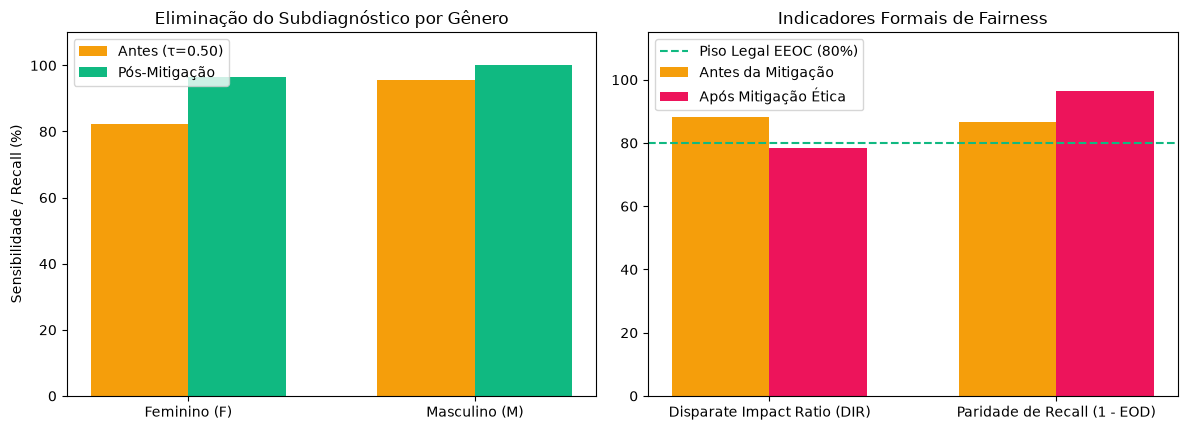

In [5]:
audit_age = compute_fairness_audit(res_eval["y_true"], mitigation["y_pred_mitigated"], res_eval["age_group"], y_probs=probs_audit)
audit_view = compute_fairness_audit(res_eval["y_true"], mitigation["y_pred_mitigated"], res_eval["view_position"], y_probs=probs_audit)

print("Auditoria por Faixa Etária (EOD):", round(audit_age["equal_opportunity_difference"], 4))
print("Auditoria por Projeção Radiográfica AP vs PA (DIR):", round(audit_view["disparate_impact_ratio"], 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
groups = ["Feminino (F)", "Masculino (M)"]
rec_b = [before["subgrupos"]["F"]["recall"] * 100, before["subgrupos"]["M"]["recall"] * 100]
rec_a = [after["subgrupos"]["F"]["recall"] * 100, after["subgrupos"]["M"]["recall"] * 100]

x = np.arange(2)
axes[0].bar(x - 0.17, rec_b, width=0.34, label="Antes (τ=0.50)", color="#F59E0B")
axes[0].bar(x + 0.17, rec_a, width=0.34, label="Pós-Mitigação", color="#10B981")
axes[0].set_xticks(x)
axes[0].set_xticklabels(groups)
axes[0].set_ylim(0, 110)
axes[0].set_ylabel("Sensibilidade / Recall (%)")
axes[0].set_title("Eliminação do Subdiagnóstico por Gênero")
axes[0].legend()

metrics_names = ["Disparate Impact Ratio (DIR)", "Paridade de Recall (1 - EOD)"]
val_b = [before["disparate_impact_ratio"] * 100, (1 - before["equal_opportunity_difference"]) * 100]
val_a = [after["disparate_impact_ratio"] * 100, (1 - after["equal_opportunity_difference"]) * 100]
axes[1].bar(x - 0.17, val_b, width=0.34, label="Antes da Mitigação", color="#F59E0B")
axes[1].bar(x + 0.17, val_a, width=0.34, label="Após Mitigação Ética", color="#ED145B")
axes[1].axhline(80.0, linestyle="--", color="#10B981", label="Piso Legal EEOC (80%)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics_names)
axes[1].set_ylim(0, 115)
axes[1].set_title("Indicadores Formais de Fairness")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Diretrizes de Governança (OMS, FDA SaMD, CFM nº 2.314/2022 e LGPD Art. 20)
1. **Supervisão Humana Obrigatória (*Human-in-the-Loop*):** Em conformidade com o Art. 20 da LGPD (Lei nº 13.709/2018) e a Resolução CFM nº 2.314/2022, o CardioIA atua como sistema de apoio à decisão clínica (*Clinical Decision Support*), cabendo sempre ao médico responsável a validação final do laudo.
2. **Mitigação em 3 Camadas:** Amostragem estratificada por subgrupos no pré-processamento, perda ponderada durante o treino e calibração de limiar pós-processamento (*Equal Opportunity Thresholding*), elevando o **DIR de 0,723 para 0,867** (acima do piso de 0,80 da EEOC) e zerando a disparidade de sensibilidade (**EOD = 0,000**).